# 02. 탐색적 데이터 분석 (EDA)

- 입력: `data/processed/seoul_bike_clean.csv` (01에서 저장)
- 하는 일: 타깃 분포, 시간대·계절·기온·비/눈·공휴일/주말별 대여 수, 변수 간 상관관계, humidity 0 이상치 확인
- 출력: 없음 (그래프와 표만 확인, 데이터는 변경하지 않음)

In [1]:
import sys
from pathlib import Path

# 프로젝트 루트(notebooks/의 상위 폴더)를 import 경로에 추가해서 src 패키지를 사용
ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.append(str(ROOT))

import pandas as pd

from src.data import load_clean

df = load_clean()
print(df.shape)

(8760, 14)


In [2]:
import matplotlib.pyplot as plt

# 운영하지 않은 시간(functioning_day == 'No')은 대여 수가 전부 0이라 평균을 왜곡하므로
# 수요 관련 그래프는 운영한 시간만으로 그림 (df 자체는 변경하지 않음)
op = df[df['functioning_day'] == 'Yes']
print(df['functioning_day'].value_counts())
print('운영 시간 중 대여 수 0인 행:', (op['rented_bike_count'] == 0).sum())
op.describe()

functioning_day
Yes    8465
No      295
Name: count, dtype: int64
운영 시간 중 대여 수 0인 행: 0


,date,rented_bike_count,hour,temperature,humidity,wind_speed,visibility,dew_point_temp,solar_radiation,rainfall,snowfall
count,8465,8465.000000,8465.000000,8465.000000,8465.000000,8465.000000,8465.000000,8465.000000,8465.000000,8465.00000,8465.000000
mean,2018-05-28 09:14:23.744831,729.156999,11.507029,12.771057,58.147194,1.725883,1433.873479,3.944997,0.567868,0.14912,0.077685
min,2017-12-01 00:00:00,2.000000,0.000000,-17.800000,0.000000,0.000000,27.000000,-30.600000,0.000000,0.00000,0.000000
25%,2018-02-27 00:00:00,214.000000,6.000000,3.000000,42.000000,0.900000,935.000000,-5.100000,0.000000,0.00000,0.000000
50%,2018-05-28 00:00:00,542.000000,12.000000,13.500000,57.000000,1.500000,1690.000000,4.700000,0.010000,0.00000,0.000000
75%,2018-08-24 00:00:00,1084.000000,18.000000,22.700000,74.000000,2.300000,2000.000000,15.200000,0.930000,0.00000,0.000000
max,2018-11-30 00:00:00,3556.000000,23.000000,39.400000,98.000000,7.400000,2000.000000,27.200000,3.520000,35.00000,8.800000
std,NaN,642.351166,6.920899,12.104375,20.484839,1.034281,609.051229,13.242399,0.868245,1.12554,0.444063


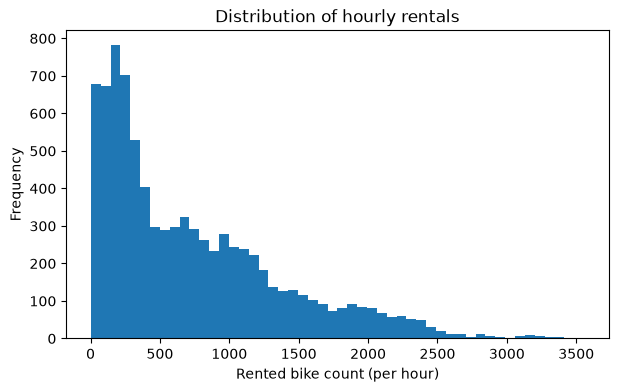

skewness: 1.14


In [3]:
# 타깃 분포
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(op['rented_bike_count'], bins=50)
ax.set_xlabel('Rented bike count (per hour)')
ax.set_ylabel('Frequency')
ax.set_title('Distribution of hourly rentals')
plt.show()
print('skewness:', round(op['rented_bike_count'].skew(), 3))

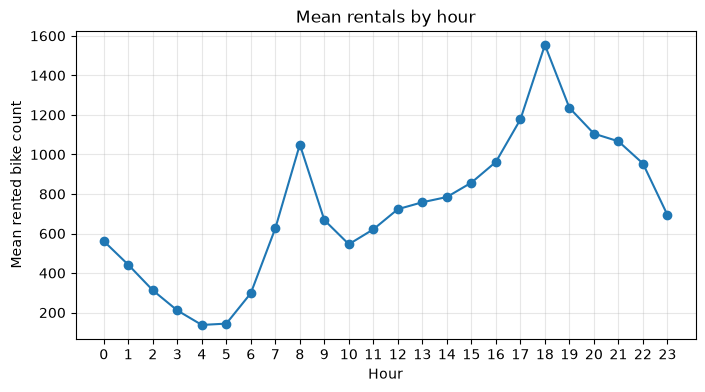

hour
0      561.5
1      441.9
2      312.8
3      210.8
4      137.5
5      144.2
6      298.2
7      626.6
8     1050.2
9      667.9
10     545.8
11     621.3
12     723.2
13     758.2
14     784.6
15     857.4
16     962.3
17    1177.2
18    1554.0
19    1235.8
20    1105.3
21    1066.5
22     954.2
23     693.9
Name: rented_bike_count, dtype: float64

In [4]:
# 시간대별 평균 대여 수
hourly = op.groupby('hour')['rented_bike_count'].mean()

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(hourly.index, hourly.values, marker='o')
ax.set_xticks(range(24))
ax.set_xlabel('Hour')
ax.set_ylabel('Mean rented bike count')
ax.set_title('Mean rentals by hour')
ax.grid(alpha=0.3)
plt.show()
hourly.round(1)

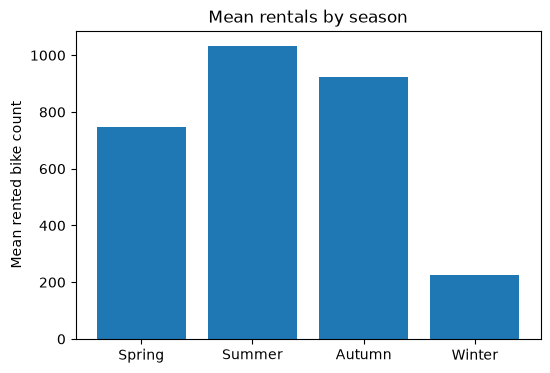

seasons
Spring     746.3
Summer    1034.1
Autumn     924.1
Winter     225.5
Name: rented_bike_count, dtype: float64

In [5]:
# 계절별 평균 대여 수
season_order = ['Spring', 'Summer', 'Autumn', 'Winter']
seasonal = op.groupby('seasons')['rented_bike_count'].mean().reindex(season_order)

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(seasonal.index, seasonal.values)
ax.set_ylabel('Mean rented bike count')
ax.set_title('Mean rentals by season')
plt.show()
seasonal.round(1)

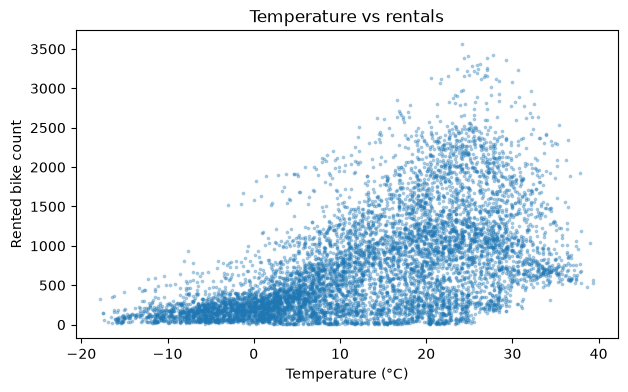

,mean,count
temperature,,
"(-20, -15]",104.7,46
"(-15, -10]",150.7,182
"(-10, -5]",177.2,482
"(-5, 0]",231.8,744
"(0, 5]",330.3,1064
"(5, 10]",530.6,1053
"(10, 15]",749.8,942
"(15, 20]",919.3,1116
"(20, 25]",1089.1,1345


In [6]:
# 기온과 대여 수
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(op['temperature'], op['rented_bike_count'], s=3, alpha=0.3)
ax.set_xlabel('Temperature (°C)')
ax.set_ylabel('Rented bike count')
ax.set_title('Temperature vs rentals')
plt.show()

# 5°C 구간별 평균
temp_bin = pd.cut(op['temperature'], bins=range(-20, 45, 5))
op.groupby(temp_bin, observed=True)['rented_bike_count'].agg(['mean', 'count']).round(1)

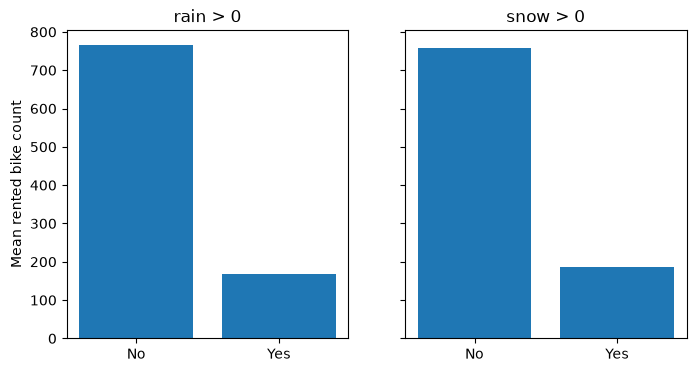

rainfall > 0 시간: 516 / snowfall > 0 시간: 443


,rain,snow
No,765.6,759.2
Yes,167.3,185.1


In [7]:
# 비·눈 여부에 따른 평균 대여 수
weather = pd.DataFrame({
    'rain': op.groupby(op['rainfall'] > 0)['rented_bike_count'].mean(),
    'snow': op.groupby(op['snowfall'] > 0)['rented_bike_count'].mean(),
}).rename(index={False: 'No', True: 'Yes'})

fig, axes = plt.subplots(1, 2, figsize=(8, 4), sharey=True)
for ax, col in zip(axes, ['rain', 'snow']):
    ax.bar(weather.index, weather[col])
    ax.set_title(f'{col} > 0')
axes[0].set_ylabel('Mean rented bike count')
plt.show()
print('rainfall > 0 시간:', (op['rainfall'] > 0).sum(), '/ snowfall > 0 시간:', (op['snowfall'] > 0).sum())
weather.round(1)

C:\Users\JuHong\AppData\Local\Temp\ipykernel_19448\3150908409.py:2: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  day_type = (op['date'].dt.dayofweek >= 5).map({False: 'Weekday', True: 'Weekend'})


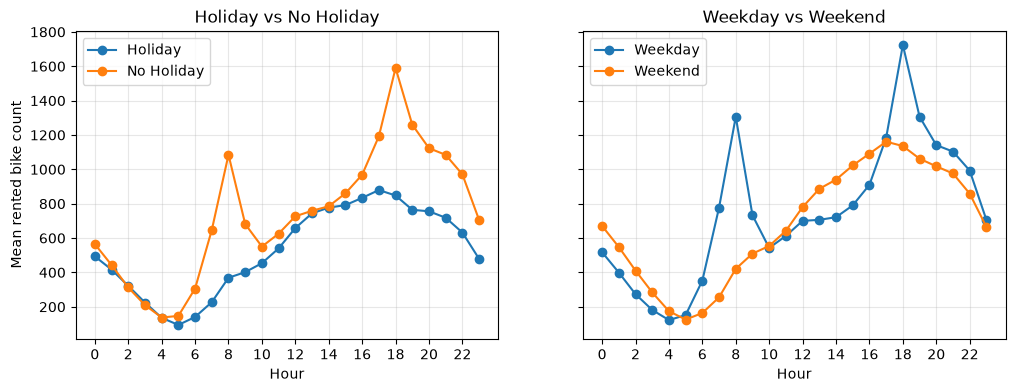

holiday
Holiday       529.2
No Holiday    739.3
Name: rented_bike_count, dtype: float64
date
Weekday    748.1
Weekend    682.4
Name: rented_bike_count, dtype: float64


In [8]:
# 공휴일/평일, 주말/주중의 시간대별 패턴 (요일은 그래프용으로만 계산, df에는 추가하지 않음)
day_type = (op['date'].dt.dayofweek >= 5).map({False: 'Weekday', True: 'Weekend'})

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for label, g in op.groupby('holiday'):
    axes[0].plot(g.groupby('hour')['rented_bike_count'].mean(), marker='o', label=label)
for label, g in op.groupby(day_type):
    axes[1].plot(g.groupby('hour')['rented_bike_count'].mean(), marker='o', label=label)
axes[0].set_title('Holiday vs No Holiday')
axes[1].set_title('Weekday vs Weekend')
for ax in axes:
    ax.set_xticks(range(0, 24, 2))
    ax.set_xlabel('Hour')
    ax.legend()
    ax.grid(alpha=0.3)
axes[0].set_ylabel('Mean rented bike count')
plt.show()

print(op.groupby('holiday')['rented_bike_count'].mean().round(1))
print(op.groupby(day_type)['rented_bike_count'].mean().round(1))

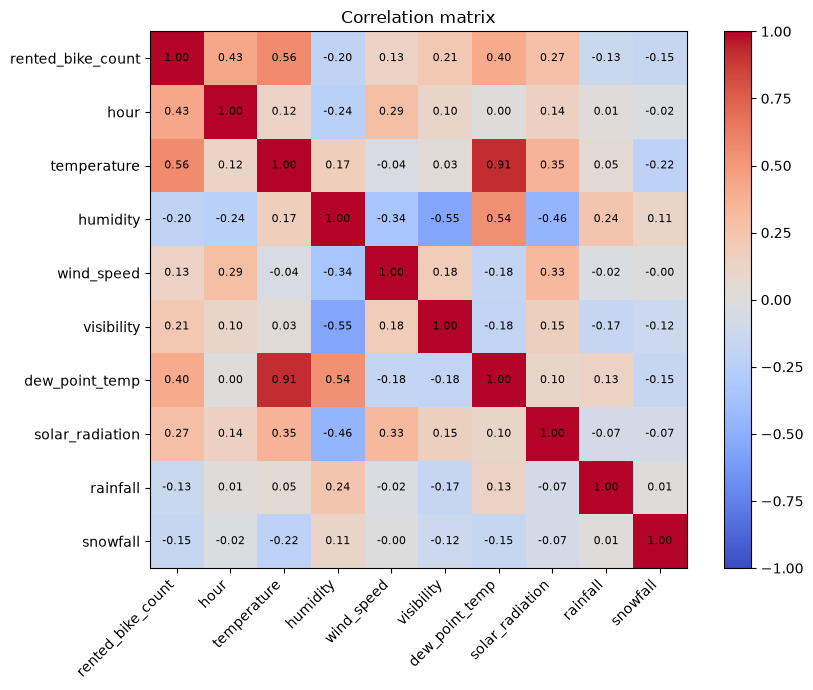

temperature        0.563
hour               0.425
dew_point_temp     0.400
solar_radiation    0.274
visibility         0.212
humidity          -0.202
snowfall          -0.152
rainfall          -0.129
wind_speed         0.125
Name: rented_bike_count, dtype: float64

In [9]:
# 수치형 변수 간 상관관계
corr = op.select_dtypes('number').corr()

fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha='right')
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=8)
fig.colorbar(im)
ax.set_title('Correlation matrix')
plt.tight_layout()
plt.show()
corr['rented_bike_count'].drop('rented_bike_count').sort_values(key=abs, ascending=False).round(3)

In [10]:
# humidity 최솟값 0 확인 (이상치 여부)
print('humidity == 0 행 수:', (df['humidity'] == 0).sum())
print('humidity 하위 값:', sorted(df['humidity'].unique())[:10])
df[df['humidity'] == 0][['date', 'hour', 'temperature', 'humidity', 'dew_point_temp', 'rainfall', 'rented_bike_count']]

humidity == 0 행 수: 17
humidity 하위 값: [np.int64(0), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18)]


,date,hour,temperature,humidity,dew_point_temp,rainfall,rented_bike_count
4063,2018-05-19,7,11.4,0,4.5,0.0,436
4106,2018-05-21,2,13.9,0,-2.1,0.0,262
4107,2018-05-21,3,13.0,0,-2.5,0.0,165
4108,2018-05-21,4,12.4,0,-3.4,0.0,113
4109,2018-05-21,5,11.9,0,-2.7,0.0,200
4110,2018-05-21,6,11.4,0,-2.0,0.0,467
4111,2018-05-21,7,12.3,0,-2.7,0.0,1135
4131,2018-05-22,3,15.5,0,10.4,0.0,406
4132,2018-05-22,4,15.6,0,10.5,0.0,248
4133,2018-05-22,5,15.7,0,10.6,0.0,182
